# 12 Final Overlay Test (финальный тест с оверлеем)

Этот notebook (ноутбук) строит итоговый `test portfolio (тестовый портфель)` из трех корзин:

- `two_option_improved (улучшенные двухопционным фильтром)`;
- `core_only (только базовые стратегии)`, если `put overlay (пут-оверлей)` на `train (обучении)` не прошел правило;
- `core_put_overlay (базовые стратегии с пут-оверлеем)`, если `put overlay (пут-оверлей)` на `train (обучении)` снизил `drawdown (просадку)` и сохранил `PnL (прибыль и убыток)`.

График сравнения содержит горизонтальный уровень финального `PnL (прибыли и убытка)` старого портфеля.

## Overlay Rule (правило оверлея)

`put overlay (пут-оверлей)` включается, если на `train (обучении)`:

- `drawdown_reduction (снижение просадки) > 0`;
- `pnl_retention (сохранение прибыли) >= 0.85`;
- `overlay_drawdown_to_pnl (просадка к прибыли после оверлея) < core_drawdown_to_pnl (просадка к прибыли базовой стратегии)`.

In [1]:
from pathlib import Path
import sys
import pandas as pd
from IPython.display import Image, display

WORK_ROOT = Path(r'./workspace')
if str(WORK_ROOT) not in sys.path:
    sys.path.insert(0, str(WORK_ROOT))

from final_overlay_test import run_final_overlay_test

manifest = run_final_overlay_test()
manifest

{'test_start': '2020-01-01 00:00:00',
 'test_end': '2023-08-10 23:59:59',
 'n_strategies': 664,
 'n_two_option': 236,
 'n_core_put_overlay': 308,
 'n_core_only': 120,
 'n_errors': 0,
 'old_portfolio_total': 213.90956556189184,
 'new_portfolio_total': 205.23674527563145,
 'plots': ['D:\\Filter_2_option_v2\\12_final_overlay_test_output\\plots\\01_final_overlay_vs_old_pnl.png',
  'D:\\Filter_2_option_v2\\12_final_overlay_test_output\\plots\\02_final_overlay_vs_old_drawdown.png'],
 'output_dir': 'D:\\Filter_2_option_v2\\12_final_overlay_test_output'}

## Portfolio Comparison (сравнение портфелей)

In [2]:
OUTPUT_DIR = Path(r'D:\Filter_2_option_v2\12_final_overlay_test_output')
pd.read_csv(OUTPUT_DIR / '04_portfolio_comparison.csv')

,portfolio_name,portfolio_total,portfolio_max_drawdown,portfolio_sharpe,portfolio_sortino,portfolio_hit_rate,portfolio_profit_factor,n_strategies,n_instruments,core_total,gross_total,cost_gap
0,old_664_portfolio,213.909566,-15.443685,3.136417,4.097159,0.517413,1.113502,664,73.0,-18.140212,71.305088,89.4453
1,final_overlay_portfolio,205.236745,-15.409530,3.301012,4.468756,0.515334,1.118328,664,NaN,-18.140212,71.305088,89.4453


## Group Summary (сводка по группам)

In [3]:
pd.read_csv(OUTPUT_DIR / '05_group_summary.csv')

,basket,filter_group,n_strategies,n_positive,n_improved,total_test_pnl,median_test_pnl,median_sharpe,median_sortino,median_drawdown_to_pnl
0,core_put_overlay,put_overlay,308,209,93,100.785126,0.118095,0.277190,0.268651,1.358666
1,two_option_improved,two_option,236,196,210,64.067351,0.093374,0.933970,0.427689,0.454549
2,core_only,core_only,120,78,0,40.384268,0.080100,0.184901,0.176208,1.460252


## Strategy Results (результаты стратегий)

In [4]:
results = pd.read_csv(OUTPUT_DIR / '01_final_overlay_strategy_results.csv')
results.head(50)

,spec_id,strategy_id,basket,filter_group,instrument,use_put_overlay,core_test_total,core_test_sharpe,core_test_sortino,core_test_max_drawdown,...,t_bars,std_span,k_shift_sigma,center_scale,overlay_weight,test_n_obs,test_start,test_end,test_gross_total,test_cost_gap_core
0,785,DX_E6__pair_spread_momentum__window_88__z_1.5,two_option_improved,two_option,NaN,False,-0.265702,-20.876711,-18.331945,-0.265854,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,783,DX_E6__pair_spread_momentum__window_88__z_1.0,two_option_improved,two_option,NaN,False,-0.301161,-19.106965,-20.590997,-0.301593,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,821,E6_DX__pair_spread_momentum__window_88__z_1.5,two_option_improved,two_option,NaN,False,-0.258958,-19.743646,-17.473318,-0.259080,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,495,A6_N6__pair_spread_momentum__window_88__z_1.0,two_option_improved,two_option,NaN,False,-6.101766,-2.048459,-1.959980,-6.588834,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,781,DX_E6__pair_spread_momentum__window_88__z_0.5,two_option_improved,two_option,NaN,False,-0.307784,-17.111557,-21.336706,-0.308518,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5,819,E6_DX__pair_spread_momentum__window_88__z_1.0,two_option_improved,two_option,NaN,False,-0.295341,-18.219383,-20.254826,-0.296070,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
6,817,E6_DX__pair_spread_momentum__window_88__z_0.5,two_option_improved,two_option,NaN,False,-0.314869,-16.527628,-20.353422,-0.315740,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
7,501,A6_N6__pair_spread_momentum__window_176__z_1.0,two_option_improved,two_option,NaN,False,-3.085379,-1.043090,-1.033842,-3.756396,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
8,789,DX_E6__pair_spread_momentum__window_176__z_1.0,two_option_improved,two_option,NaN,False,-0.217028,-13.875948,-14.509763,-0.217762,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
9,787,DX_E6__pair_spread_momentum__window_176__z_0.5,two_option_improved,two_option,NaN,False,-0.224203,-12.632556,-15.555295,-0.225255,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## Plots (графики)

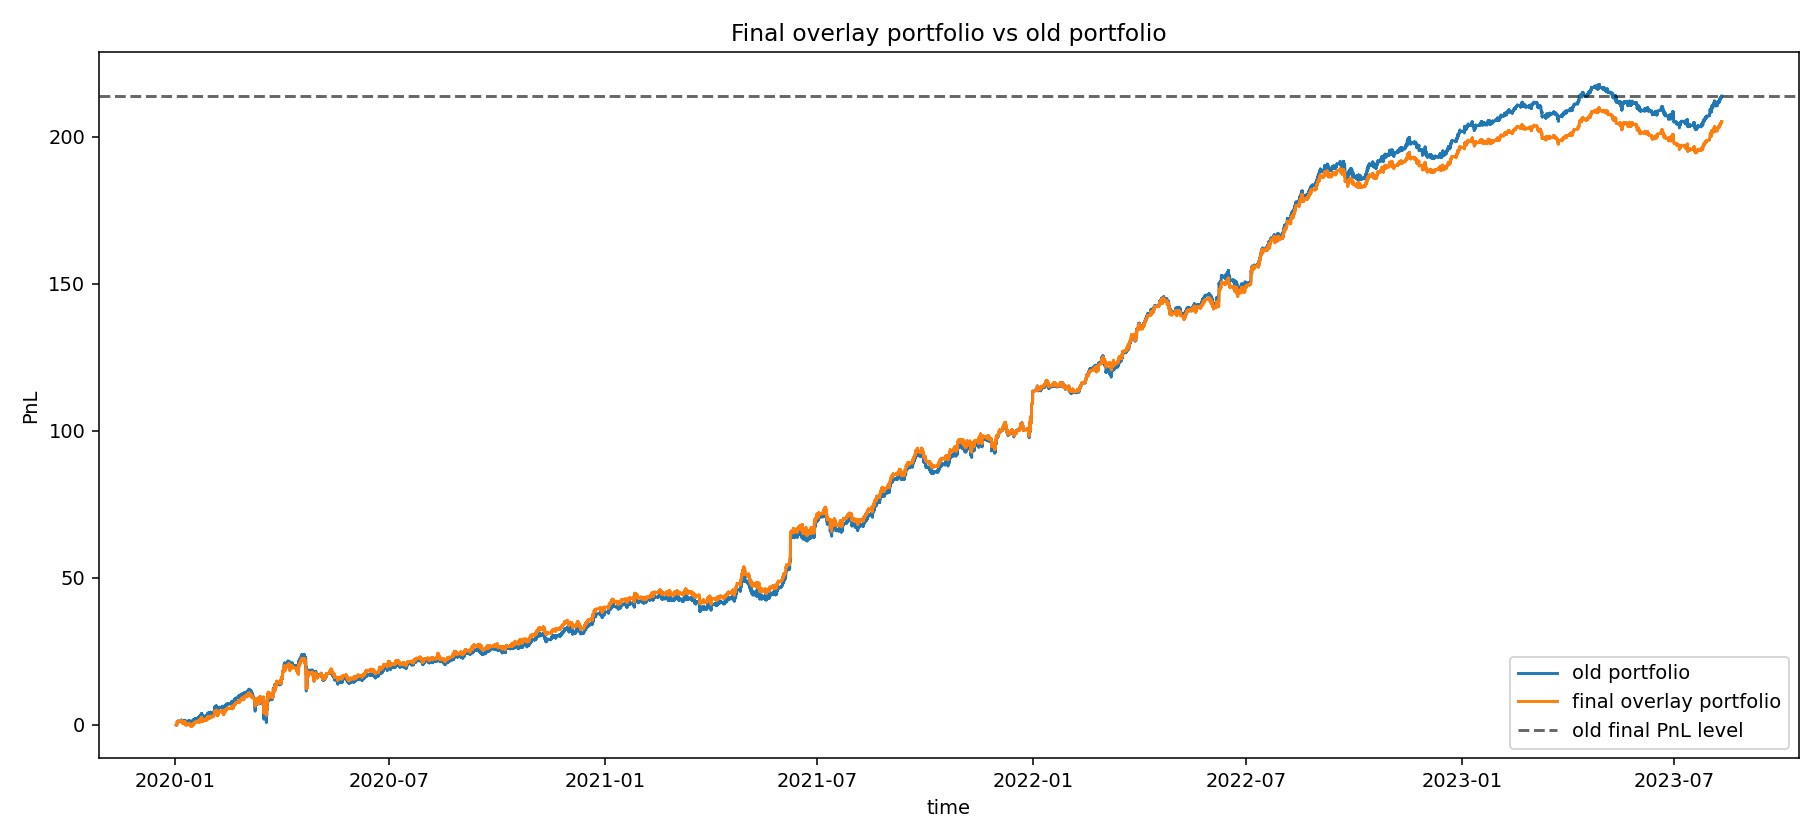

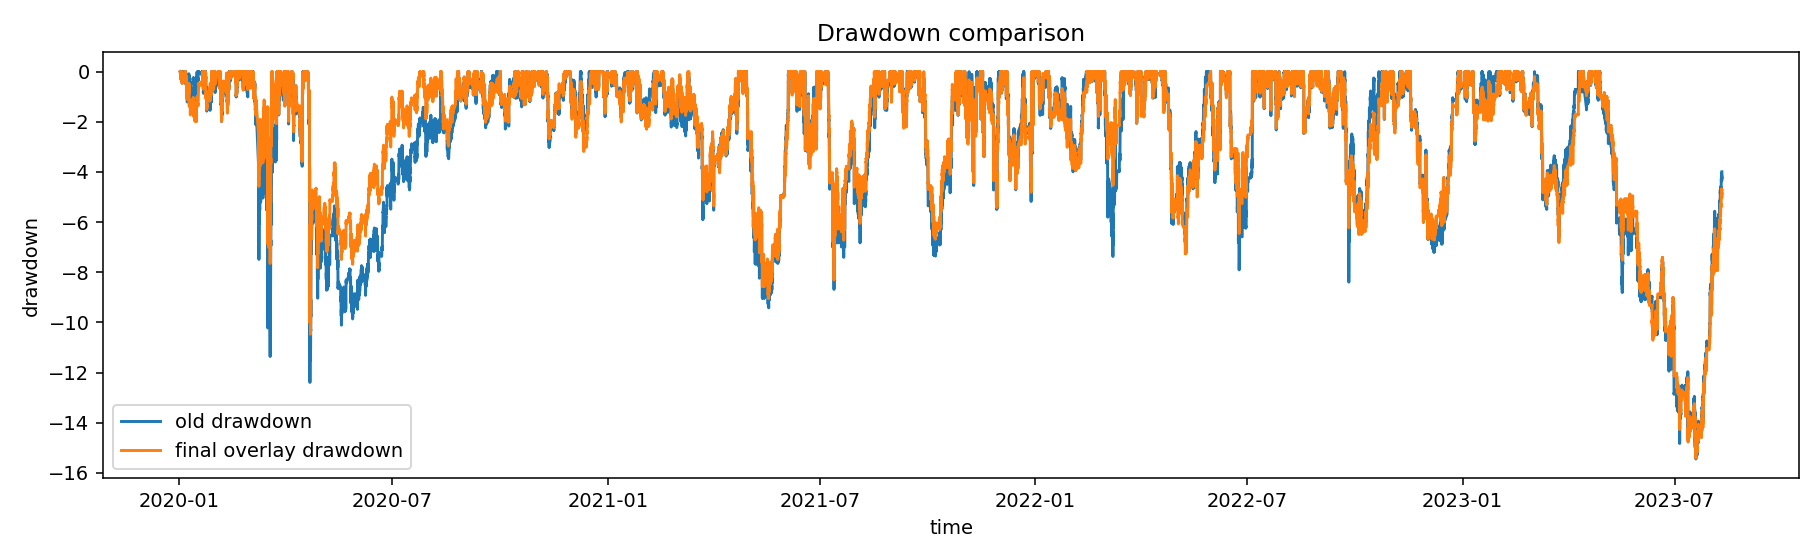

In [5]:
for name in ['01_final_overlay_vs_old_pnl.png', '02_final_overlay_vs_old_drawdown.png']:
    display(Image(filename=str(OUTPUT_DIR / 'plots' / name)))

## Errors (ошибки)

In [6]:
pd.read_csv(OUTPUT_DIR / '07_errors.csv')

,spec_id,strategy_id,basket,error
